# Chile: CMF B-1, IFRS 9 and the Bank of Spain Annex 9 on one portfolio (Banco Andino)

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 04 of this topic
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- say why Chilean banks do not book IFRS 9 impairment on loans, and where the CMF's B-1 provisions come from;
- read the B-1 standard method, the factor $PE = PI \times PDI$ by group, the maximum rule between the standard and an internal method, the 0.50% minimum and the additional provisions, and compute each with the engine on constructed accounts;
- read the Bank of Spain Annex 9 coverage tables and the mapping of its categories to the IFRS 9 stages;
- provision one synthetic bank under the three regimes, and read the gap between B-1 and IFRS 9 as a bridge of measurement choices;
- say what happens to the gap between the regimes when the economy is stressed in five different ways.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C07, **Banco Andino**, a **synthetic** bank generated and calibrated to public aggregates of the CMF, Chile's financial market commission. It is not a real bank and not evidence about any bank; the committed notice says so, and the notebook prints it. Its book has six segments (mortgages by loan-to-value, consumer instalment loans, cards, and commercial loans by group or individual assessment) and about 171,000 accounts, in Chilean pesos (CLP). The same book is provisioned under three regimes and under six scenarios, one file each.

- **Files read:** `data/derived/C07/base.json`, `recession.json`, `house-price-fall.json`, `consumer-arrears-shock.json`, `uf-inflation-spike.json` and `combined-severe.json`, and `data/derived/C07/models-banco-andino.json` for the model slots. In each scenario file: `outputs.comparison` (the three provisions by segment), `outputs.gap_bridge`, `outputs.b1_detail`, `outputs.ifrs9_detail`, `outputs.bde_detail` and, from the second scenario on, `outputs.delta_vs_base`.
- **The regimes:** CMF B-1 is the statutory provision Chilean banks book on loans; the IFRS 9 column is a **comparison measure** and not what Chilean banks book (CNCB chapter A-2 N 5 leaves loans to B-1); the Bank of Spain Annex 9 is the Spanish GAAP alternative solution.
- **Assumptions of the case:** the scenario shocks, the overlays and the additional provisions are assumptions of the case, not Chilean paths or data.

The next cell loads the six scenarios and the model file and prints the committed notice, the model slots and the engine versions.

In [2]:
# Load the six scenarios of Banco Andino and the model file, and print the notice and the model slots
from riskvalidation.provisions import local_cl as cl, local_es as es

LANG = "en"
ROOT = Path("../../..").resolve()
NAMES = ["base", "recession", "house-price-fall", "consumer-arrears-shock", "uf-inflation-spike", "combined-severe"]


def read(name):
    return json.loads((ROOT / "data" / "derived" / "C07" / f"{name}.json").read_text(encoding="utf-8"))


scenarios = {name: read(name) for name in NAMES}
models = read("models-banco-andino")
base = scenarios["base"]["outputs"]
print(base["notice"][LANG])
print("synthetic:", base["synthetic"], "|", scenarios["base"]["provenance"]["truth_status"], "| currency:", base["currency"])
print("model slots:", [(m["id"], m["engine"]) for m in models["model"]])
print("baked by engine:", {n: s["provenance"]["riskvalidation_version"] for n, s in scenarios.items()}, "| installed engine:", md.version("riskvalidation"))
print("accounts:", sum(seg["accounts"] for seg in base["portfolio"]["segments"]), "| gross exposure, CLP billions:", round(sum(seg["gross_exposure"] for seg in base["portfolio"]["segments"]) / 1e9, 1))

Synthetic data: Banco Andino is a generated bank calibrated to public CMF system aggregates, not a real bank and not evidence about any bank. CMF B-1 is the statutory provision Chilean banks book on loans; the IFRS 9 column is a comparison measure, not the provision Chilean banks book on loans (CNCB A-2 N 5 leaves loans to B-1); BdE Annex 9 is the Spanish GAAP alternative solution. Amounts in CLP.
synthetic: True | synthetic-calibrated | currency: CLP
model slots: [('G0-banco-andino', 'none'), ('B1-standard', 'riskvalidation.provisions.local_cl'), ('IFRS9-ecl', 'riskvalidation.provisions.ecl'), ('BDE-annex9', 'riskvalidation.provisions.local_es')]
baked by engine: {'base': '1.0.1', 'recession': '1.0.1', 'house-price-fall': '1.0.1', 'consumer-arrears-shock': '1.0.1', 'uf-inflation-spike': '1.0.1', 'combined-severe': '1.0.1'} | installed engine: 1.0.1
accounts: 171500 | gross exposure, CLP billions: 6000.0


## Method

**Why three regimes.** Chilean banks adopted IFRS 9 in the CMF's accounting compendium (CNCB) in 2022 **except** the impairment chapter for loans: the provisions on loans and contingent credits stay under chapters B-1 to B-3 (CNCB A-2 N 5). The B-1 provision is a supervisory formula, not an expected credit loss. Spanish banks, under Circular 4/2017 of the Bank of Spain, do apply the IFRS 9 model, with supervisory "alternative solutions" for the collective estimate. Contraste provisions one synthetic bank under the three, to show where they agree and where they do not.

**CMF B-1, the standard methods** (CNCB B-1 N 3). For a group portfolio the provision factor is the product of the probability of default and the loss given default of the cell of a table, by exposure group and days past due:

$$PE = PI \times PDI, \qquad \mathrm{Prov}_{\mathrm{group}} = EG\,(1 - s)\,PE_{\mathrm{group}} + EG\,s\,PE_{\mathrm{guarantor}}, \qquad \mathrm{Prov} = \max\bigl(\mathrm{Prov}^{\mathrm{standard}}, \mathrm{Prov}^{\mathrm{internal}}\bigr)$$

with $EG$ the group exposure and $s$ the guaranteed share (B-1 N 4.1); the maximum rule applies unless the internal method has the CMF's "no objection" (B-1 N 3). An individually assessed debtor has a category A1 to A6 (normal) or B1 to B4 (substandard) with its own $PE$ (N 2.1). The minimum provision of 0.50% applies to the individually assessed normal portfolio only, and the additional (counter-cyclical) provisions are a separate line, inside the board's policy limits and never part of the comparable total (N 9).

**The Bank of Spain Annex 9** (Circular 4/2017, as amended by Circular 6/2021, tables of points 140, 144 and 172 from 30 June 2022). The coverage is a coefficient of the amount not covered by effective guarantees, by segment and risk category:

$$\mathrm{Coverage} = c_{s,k}\,\max\Bigl(0,\ \mathrm{EAD} - \sum_g \mathrm{AdjustedValue}_g\Bigr)$$

with normal and special-watch risk by point 144, doubtful risk by arrears by point 140, and the mapping of categories to stages (normal to Stage 1, special watch to Stage 2, doubtful to Stage 3).

**IFRS 9 as a comparison measure** is the probability-weighted ECL of notebooks 01 to 03 with overlays as separate lines (notebook 04). The engine's functions compute and state no compliance claim; the Annex 9 point numbers are those of Circular 6/2021 and whether they moved after Circular 1/2025 is not verified here.

### Step 1: the B-1 tables, cell by cell

The engine holds the B-1 tables transcribed cell by cell, with the source paragraph in the code. We call the lookups on **constructed** accounts to read the tables: a residential mortgage by loan-to-value (PVG, the outstanding principal over the collateral value) and days past due, a commercial loan with and without guarantee, and a consumer loan. Each returns $(PI, PDI, PE)$. For the mortgage cells the transcribed $PE$ equals $PI \times PDI$ within the table's own rounding, which the cell checks. The mortgage cell of 40% to 80% at zero days is the one the research quotes: 0.0421% as a decimal, 0.000421.

In [3]:
# Read the B-1 mortgage, commercial and consumer cells for constructed accounts and check PE = PI x PDI
print("mortgage: PVG, days past due -> (PI, PDI, PE)")
for pvg in (0.35, 0.60, 0.85, 0.95):
    for dpd in ("0", "30-59", "default"):
        pi, pdi, pe = cl.b1_mortgage_pe(pvg, dpd)
        print(f"  PVG {pvg:.2f} | {dpd:8s} | PI {pi:.6f} | PDI {pdi:.6f} | PE {pe:.6f} | PI x PDI {pi * pdi:.6f}")
print("PE equals PI x PDI within 5e-7 in all twenty mortgage cells:", all(abs(cl.b1_mortgage_pe(v, d)[2] - cl.b1_mortgage_pe(v, d)[0] * cl.b1_mortgage_pe(v, d)[1]) <= 5e-7 for v in (0.3, 0.6, 0.85, 0.95) for d in ("0", "1-29", "30-59", "60-89", "default")))
print("commercial, current: with a guarantee at this PTVG, and without:", 0.8, [round(v, 6) for v in cl.b1_commercial_pe("0", 0.8)], [round(v, 6) for v in cl.b1_commercial_pe("0", None)])
print("consumer instalment loan, 5 days late, mortgage in the system, no arrears:", [round(v, 6) for v in cl.b1_consumer_pe(5, True, False, "instalment")])
print("individual categories A1, A4, B4 (PI, PDI, PE):", [tuple(round(v, 6) for v in cl.b1_individual_category(c)) for c in ("A1", "A4", "B4")])
try:
    cl.b1_mortgage_pe(0.6, "45")
except ValueError as error:
    print("refused:", type(error).__name__)

mortgage: PVG, days past due -> (PI, PDI, PE)
  PVG 0.35 | 0        | PI 0.010916 | PDI 0.000225 | PE 0.000002 | PI x PDI 0.000002
  PVG 0.35 | 30-59    | PI 0.460536 | PDI 0.000482 | PE 0.000222 | PI x PDI 0.000222
  PVG 0.35 | default  | PI 1.000000 | PDI 0.000537 | PE 0.000537 | PI x PDI 0.000537
  PVG 0.60 | 0        | PI 0.019158 | PDI 0.021955 | PE 0.000421 | PI x PDI 0.000421
  PVG 0.60 | 30-59    | PI 0.520824 | PDI 0.029192 | PE 0.015204 | PI x PDI 0.015204
  PVG 0.60 | default  | PI 1.000000 | PDI 0.030413 | PE 0.030413 | PI x PDI 0.030413
  PVG 0.85 | 0        | PI 0.025150 | PDI 0.215527 | PE 0.005421 | PI x PDI 0.005421
  PVG 0.85 | 30-59    | PI 0.525800 | PDI 0.219200 | PE 0.115255 | PI x PDI 0.115255
  PVG 0.85 | default  | PI 1.000000 | PDI 0.222310 | PE 0.222310 | PI x PDI 0.222310
  PVG 0.95 | 0        | PI 0.027400 | PDI 0.272000 | PE 0.007453 | PI x PDI 0.007453
  PVG 0.95 | 30-59    | PI 0.530800 | PDI 0.295900 | PE 0.157064 | PI x PDI 0.157064
  PVG 0.95 | defaul

### Step 2: the group provision, the maximum rule, the minimum and the additional provisions

`b1_group_provision` computes $EG(1-s)PE + EG\,s\,PE_{\mathrm{guarantor}}$; `b1_group_max_rule` returns the applied amount and the method; `b1_minimum_normal_check` the 0.50% test of the individually assessed normal portfolio; `b1_additional_provisions` checks an amount against the board's limits. The cell first calls them on constructed numbers, then **reproduces the committed B-1 detail of Banco Andino**: for each group segment the standard provision is the applied one because the bank has no internal method (the committed reason is recorded in English only), the minimum test is recomputed from the committed exposure and provision, and the additional provisions are within their policy range.

In [4]:
# The group provision, the maximum rule, the minimum and the additional provisions, on constructed numbers and then on the committed Banco Andino detail
print("group provision for an exposure, the group PE, the guaranteed share and the guarantor PE:", (1000.0, 0.05, 0.20, 0.01), round(cl.b1_group_provision(1000.0, 0.05, 0.20, 0.01), 4))
print("maximum rule: standard 100, internal 120; not objected; no internal method:", cl.b1_group_max_rule(100.0, 120.0), cl.b1_group_max_rule(100.0, 120.0, True), cl.b1_group_max_rule(100.0, None))
print("individual provision, exposure 1000, category A4:", cl.b1_individual_provision(1000.0, 0.0, "A4"))

detail = base["b1_detail"]
for row in detail["group_max_rule"]:
    applied, method = cl.b1_group_max_rule(row["standard"], row["internal"])
    print(f"{row['segment_id']:20s} applied, CLP millions: {applied / 1e6:10.1f} | method: {method} | same as committed: {applied == row['applied'] and method == row['method']}")
print("reason of the committed rows (first):", detail["group_max_rule"][0]["internal_reason"][LANG] if isinstance(detail["group_max_rule"][0]["internal_reason"], dict) else "in the committed record (English only)")

minimum = detail["minimum_check"]
check = cl.b1_minimum_normal_check(minimum["normal_portfolio_exposure"], minimum["normal_portfolio_provision_before_minimum"])
print("minimum of the normal portfolio: amount, binding, top-up:", round(check.minimum_amount / 1e6, 1), check.binding, check.top_up, "| committed amount:", round(minimum["minimum_amount"] / 1e6, 1))
tight = cl.b1_minimum_normal_check(minimum["normal_portfolio_exposure"], 5e9)
print("with a provision of 5 billion the minimum binds; binding, top-up in CLP millions:", tight.binding, round(tight.top_up / 1e6, 1))
extra = detail["additional_provisions"]
print("additional provisions, CLP millions, inside the policy [0, 15000]:", cl.b1_additional_provisions(extra["amount"], extra["policy_min"], extra["policy_max"]) / 1e6)
try:
    cl.b1_additional_provisions(20e9, extra["policy_min"], extra["policy_max"])
except ValueError as error:
    print("outside the policy, refused:", type(error).__name__)
print("booked B-1 total, comparable total and additional provisions, CLP millions:", round(detail["booked_total"] / 1e6, 1), round(scenarios["base"]["impact"]["provision_cmf_b1"]["value"] / 1e6, 1), round(extra["amount"] / 1e6, 1))

group provision for an exposure, the group PE, the guaranteed share and the guarantor PE: (1000.0, 0.05, 0.2, 0.01) 42.0
maximum rule: standard 100, internal 120; not objected; no internal method: (120.0, 'max') (120.0, 'internal') (100.0, 'standard')
individual provision, exposure 1000, category A4: 17.5
mortgage-ltv-le80    applied, CLP millions:     1626.7 | method: standard | same as committed: True
mortgage-ltv-gt80    applied, CLP millions:    11229.1 | method: standard | same as committed: True
consumer-instalment  applied, CLP millions:    29229.0 | method: standard | same as committed: True
consumer-cards       applied, CLP millions:    26899.5 | method: standard | same as committed: True
commercial-group     applied, CLP millions:    24191.8 | method: standard | same as committed: True
reason of the committed rows (first): in the committed record (English only)
minimum of the normal portfolio: amount, binding, top-up: 8457.4 False 0.0 | committed amount: 8457.4
with a provisi

### Step 3: the Annex 9 tables and the stage mapping

`annex9_normal_coverage` reads point 144 and `annex9_doubtful_coverage` point 140, by segment code (A.* for businesses, B.* for households) and by the age of the oldest past-due amount in days; `annex9_coverage` applies the coefficient to the uncovered amount. The cell reads a few cells for **constructed** accounts, and then checks the committed Annex 9 detail of Banco Andino: each category's coverage rate (provision over exposure) and its mapped stage against the engine's mapping `annex9_category_to_stage`.

In [5]:
# Read Annex 9 coefficients on constructed accounts and check the committed categories and their stage mapping
print("point 144, normal and special watch, B.1.1 housing:", es.annex9_normal_coverage("B.1.1", "normal"), es.annex9_normal_coverage("B.1.1", "normal-special-watch"))
print("point 144, normal, B.2 consumer and A.1.1 construction:", es.annex9_normal_coverage("B.2", "normal"), es.annex9_normal_coverage("A.1.1", "normal"))
print("point 140, B.1.1 housing, by days past due:", [(d, es.annex9_doubtful_coverage("B.1.1", d)) for d in (91, 183, 184, 365, 700)])
print("coverage: EAD 1000, adjusted guarantees 300, B.1.1 normal:", es.annex9_coverage("B.1.1", "normal", 1000.0, [300.0]))
try:
    es.annex9_coverage("B.1.1", "doubtful", 1000.0, [])
except ValueError as error:
    print("a doubtful account without days past due is refused:", type(error).__name__)

for row in base["bde_detail"]["categories"]:
    rate = row["provision"] / row["exposure"]
    print(f"{row['category']:22s} mapped stage: {row['mapped_stage']} | engine mapping agrees: {es.annex9_category_to_stage(row['category']) == row['mapped_stage']} | coverage rate, committed and recomputed: {row['coverage_rate']:.6f} {rate:.6f}")

point 144, normal and special watch, B.1.1 housing: 0.007 0.18
point 144, normal, B.2 consumer and A.1.1 construction: 0.018 0.019
point 140, B.1.1 housing, by days past due: [(91, 0.45), (183, 0.45), (184, 0.5), (365, 0.65), (700, 1.0)]
coverage: EAD 1000, adjusted guarantees 300, B.1.1 normal: 4.9
a doubtful account without days past due is refused: ValueError
normal                 mapped stage: stage1 | engine mapping agrees: True | coverage rate, committed and recomputed: 0.003723 0.003723
normal-special-watch   mapped stage: stage2 | engine mapping agrees: True | coverage rate, committed and recomputed: 0.057243 0.057243
doubtful               mapped stage: stage3 | engine mapping agrees: True | coverage rate, committed and recomputed: 0.265210 0.265210


### Step 4: one portfolio, three provisions

Now the three regimes side by side on the base scenario. `outputs.comparison` gives, for each segment, the B-1 provision, the IFRS 9 ECL and the Annex 9 coverage, and the unallocated lines (the IFRS 9 overlays). The cell recomputes the totals by summing the segments, compares them with the committed `impact` values, prints the coverage by segment and the ratio of each regime to B-1. The additional B-1 provisions are not in the comparable total.

In [6]:
# Sum the segments of each regime, compare with the committed totals and print the coverage by segment
comparison = base["comparison"]
segments = {s["segment_id"]: s for s in base["portfolio"]["segments"]}
keys = ("cmf_b1_provision", "ifrs9_provision", "bde_annex9_provision")
totals = {k: sum(r[k] for r in comparison["rows"]) + comparison["unallocated"][k] for k in keys}
committed = {"cmf_b1_provision": "provision_cmf_b1", "ifrs9_provision": "provision_ifrs9", "bde_annex9_provision": "provision_bde"}
for k in keys:
    print(f"{k:22s} sum of segments plus unallocated, CLP millions: {totals[k] / 1e6:12.1f} | committed: {scenarios['base']['impact'][committed[k]]['value'] / 1e6:12.1f}")
print("IFRS 9 over B-1, BdE over B-1:", round(totals["ifrs9_provision"] / totals["cmf_b1_provision"], 4), round(totals["bde_annex9_provision"] / totals["cmf_b1_provision"], 4))
print("coverage by segment: B-1, IFRS 9, Annex 9")
for r in comparison["rows"]:
    exposure = segments[r["segment_id"]]["gross_exposure"]
    print(f"  {r['segment_id']:24s}", *[f"{r[k] / exposure:8.4f}" for k in keys])
print("unallocated lines (IFRS 9 overlays), CLP millions:", round(comparison["unallocated"]["ifrs9_provision"] / 1e6, 1))

cmf_b1_provision       sum of segments plus unallocated, CLP millions:     152000.6 | committed:     152000.6
ifrs9_provision        sum of segments plus unallocated, CLP millions:      97592.0 | committed:      97592.0
bde_annex9_provision   sum of segments plus unallocated, CLP millions:      79618.5 | committed:      79618.5
IFRS 9 over B-1, BdE over B-1: 0.6421 0.5238
coverage by segment: B-1, IFRS 9, Annex 9
  mortgage-ltv-le80          0.0011   0.0064   0.0000
  mortgage-ltv-gt80          0.0171   0.0107   0.0038
  consumer-instalment        0.0801   0.0259   0.0441
  consumer-cards             0.0844   0.0330   0.0332
  commercial-group           0.0187   0.0088   0.0093
  commercial-individual      0.0302   0.0255   0.0197
unallocated lines (IFRS 9 overlays), CLP millions: 324.1


### Step 5: the bridge from B-1 to IFRS 9

The gap between two regimes is a sum of choices. `outputs.gap_bridge` lists the steps from the B-1 total to the IFRS 9 total: the measurement basis (the bank's PD, loss given default and recoveries against the B-1 matrices, 12 months, central, undiscounted), the lifetime horizon for Stage 2, the probability weighting of the scenarios, the discounting at the original EIR, the B-1 minimum top-up that IFRS 9 does not have, and the IFRS 9 overlays. The cell prints the steps in the language of the tree and checks that the B-1 total plus the steps equals the IFRS 9 total.

In [7]:
# Print the bridge steps and check that B-1 plus the steps equals the IFRS 9 total
bridge = base["gap_bridge"]
running = totals["cmf_b1_provision"]
print(f"{'':6s}{'B-1':>48s}: {running / 1e9:9.3f}  CLP billions")
for step in bridge["steps"]:
    running += step["amount"]
    print(f"{step['id']:24s} {step['amount'] / 1e9:+10.3f} -> {running / 1e9:9.3f}")
    print("    ", step["label"][LANG])
print("B-1 plus the steps equals the IFRS 9 total within 1 CLP:", abs(running - totals["ifrs9_provision"]) <= 1.0)
print("gap IFRS 9 minus B-1, CLP billions, committed:", round(scenarios["base"]["impact"]["gap_ifrs9_minus_b1"]["value"] / 1e9, 3))

                                                   B-1:   152.001  CLP billions
measurement-basis           -92.548 ->    59.452
     Measurement basis: bank PD, LGD and recoveries against the B-1 matrices (12-month, central, undiscounted)
lifetime-horizon            +17.134 ->    76.587
     Lifetime loss on Stage 2 accounts
forward-looking             +11.625 ->    88.212
     Probability weighting of the scenarios
discounting                  +9.056 ->    97.268
     Discounting at the original EIR
b1-minimum-top-up            +0.000 ->    97.268
     B-1 minimum top-up, not in IFRS 9
ifrs9-overlays               +0.324 ->    97.592
     IFRS 9 overlays
B-1 plus the steps equals the IFRS 9 total within 1 CLP: True
gap IFRS 9 minus B-1, CLP billions, committed: -54.409


### Step 6: the same bank under five stresses

The five stress files change the economy (a recession, a house price fall, a consumer arrears shock, a spike of UF inflation and a combined severe case) and re-provision the same book under the three regimes. The shocks are assumptions of the case. The cell prints each scenario's shocks (driver, unit, value), the provision of each regime, the ratio of IFRS 9 to B-1 and the committed change against the base. The question a supervisor and a bank both ask is whether the ranking of the regimes survives a stress.

In [8]:
# The three provisions in each scenario, their ratio and the committed change against the base
by_regime = {}
for name, art in scenarios.items():
    regimes = {r["regime"]: r["total_provision"] for r in art["outputs"]["regimes"]}
    by_regime[name] = regimes
    ratio = regimes["ifrs9"] / regimes["cmf-b1"]
    print(f"{name:24s} B-1: {regimes['cmf-b1'] / 1e9:8.1f} | IFRS 9: {regimes['ifrs9'] / 1e9:8.1f} | Annex 9: {regimes['bde-annex9'] / 1e9:8.1f} | IFRS 9 / B-1: {ratio:6.3f}")
    print("   shocks of the scenario (driver, unit, value):", [(s["driver"], s["unit"], s["value"]) for s in art["outputs"]["scenario"]["shocks"]])
delta = scenarios["combined-severe"]["outputs"]["delta_vs_base"]
print("combined severe against the base, CLP billions (B-1, IFRS 9, Annex 9):", round(delta["cmf_b1_delta"] / 1e9, 1), round(delta["ifrs9_delta"] / 1e9, 1), round(delta["bde_annex9_delta"] / 1e9, 1))
recomputed = by_regime["combined-severe"]["ifrs9"] - by_regime["base"]["ifrs9"]
print("the committed IFRS 9 change equals the difference of the totals:", abs(recomputed - delta["ifrs9_delta"]) <= 1.0)
print("IFRS 9 above B-1 in these scenarios:", [n for n, r in by_regime.items() if r["ifrs9"] > r["cmf-b1"]])

base                     B-1:    152.0 | IFRS 9:     97.6 | Annex 9:     79.6 | IFRS 9 / B-1:  0.642
   shocks of the scenario (driver, unit, value): []
recession                B-1:    197.5 | IFRS 9:    169.8 | Annex 9:    116.3 | IFRS 9 / B-1:  0.860
   shocks of the scenario (driver, unit, value): [('gdp-growth', 'percentage points', -3.0), ('unemployment', 'percentage points', 4.0), ('house-prices', 'percent', -5.0)]
house-price-fall         B-1:    168.9 | IFRS 9:    128.8 | Annex 9:     94.6 | IFRS 9 / B-1:  0.763
   shocks of the scenario (driver, unit, value): [('house-prices', 'percent', -15.0)]
consumer-arrears-shock   B-1:    178.6 | IFRS 9:    126.3 | Annex 9:     97.3 | IFRS 9 / B-1:  0.707
   shocks of the scenario (driver, unit, value): [('consumer-arrears', 'percentage points', 3.0)]
uf-inflation-spike       B-1:    166.9 | IFRS 9:    117.4 | Annex 9:     85.6 | IFRS 9 / B-1:  0.703
   shocks of the scenario (driver, unit, value): [('uf-inflation', 'percentage points',

### Step 7: the regimes and the bridge, drawn

The left panel draws the provision of each regime in each scenario, in CLP billions: the three bars of the base scenario and of the five stresses. The right panel draws the base bridge from B-1 to IFRS 9 as a waterfall: the first bar is the B-1 total, each step moves the running total, the last bar is the IFRS 9 total.

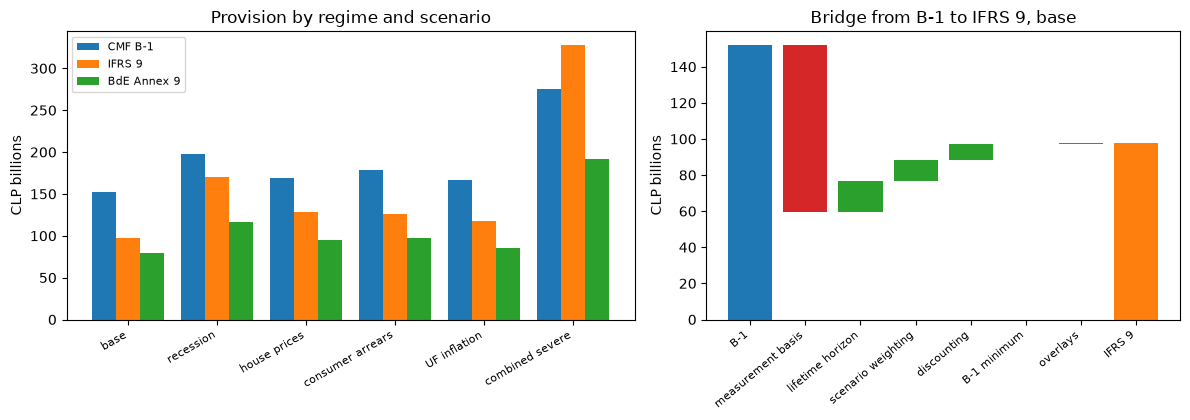

In [9]:
# Draw the provisions by regime and scenario and the bridge from B-1 to IFRS 9
SCENARIO_SHORT = {"base": "base", "recession": "recession", "house-price-fall": "house prices",
                  "consumer-arrears-shock": "consumer arrears", "uf-inflation-spike": "UF inflation", "combined-severe": "combined severe"}
STEP_SHORT = {"measurement-basis": "measurement basis", "lifetime-horizon": "lifetime horizon", "forward-looking": "scenario weighting",
              "discounting": "discounting", "b1-minimum-top-up": "B-1 minimum", "ifrs9-overlays": "overlays"}
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.2, 1]})
x = np.arange(len(NAMES))
for k, (regime, color, label) in enumerate((("cmf-b1", "tab:blue", "CMF B-1"), ("ifrs9", "tab:orange", "IFRS 9"), ("bde-annex9", "tab:green", "BdE Annex 9"))):
    left.bar(x + (k - 1) * 0.27, [by_regime[n][regime] / 1e9 for n in NAMES], width=0.27, color=color, label=label)
left.set_xticks(x)
left.set_xticklabels([SCENARIO_SHORT[n] for n in NAMES], rotation=30, ha="right", fontsize=8)
left.set_ylabel("CLP billions")
left.set_title("Provision by regime and scenario")
left.legend(fontsize=8)

level = totals["cmf_b1_provision"] / 1e9
right.bar(0, level, color="tab:blue")
labels = ["B-1"]
for i, step in enumerate(bridge["steps"], start=1):
    amount = step["amount"] / 1e9
    right.bar(i, abs(amount), bottom=level if amount >= 0 else level + amount, color="tab:green" if amount >= 0 else "tab:red")
    level += amount
    labels.append(STEP_SHORT[step["id"]])
right.bar(len(bridge["steps"]) + 1, level, color="tab:orange")
labels.append("IFRS 9")
right.set_xticks(range(len(labels)))
right.set_xticklabels(labels, rotation=40, ha="right", fontsize=8)
right.set_ylabel("CLP billions")
right.set_title("Bridge from B-1 to IFRS 9, base")
fig.tight_layout()
plt.show()

## Results

- **The B-1 tables read as transcribed.** For a mortgage with a loan-to-value (PVG) between 40% and 80% and no arrears, $PI = 0.019158$ and $PDI = 0.021955$, so $PE = 0.000421$ (0.0421%); at a PVG up to 40% it is 0.000002, and in default above 90% it is 0.302436. In all twenty cells the transcribed $PE$ equals $PI \times PDI$ within 5e-7. A current commercial loan with a guarantee at a PTVG of 0.8 has $PE = 0.005989$ and without a guarantee 0.027938; the consumer instalment loan of the example has 0.015741; the individual categories A1, A4 and B4 have 0.00036, 0.0175 and 0.43875.
- **The group rules compute as the compendium says.** With an exposure of 1,000, a $PE$ of 0.05 and 20% guaranteed at 0.01 the provision is 42.0; the maximum rule gives 120 for a standard 100 and an internal 120, the internal 120 when it is not objected to, and 100 without an internal method. Banco Andino has no internal method, so the standard provision is the applied one in all five group segments, equal to the committed values (the committed reason is recorded in English only).
- **The minimum and the additional provisions are separate.** The 0.50% minimum of the individually assessed normal portfolio is 8,457.4 millions of CLP, equal to the committed amount, and does not bind; with a provision of 5,000 millions it would bind with a top-up of 3,457.4. The additional provisions of 3,000 millions are inside the board's range of 0 to 15,000, and 20,000 is refused. The booked B-1 total, 155,000.6 millions, is the comparable total, 152,000.6, plus the additional provisions.
- **Annex 9 reads as a coefficient on the uncovered amount.** Housing normal risk is 0.007 and special watch 0.18; consumer credit 0.018; construction 0.019. For doubtful housing risk the coefficient is 0.45 up to 183 days, 0.50 from 184, 0.65 at 365 and 1.0 at 700; an account of 1,000 with guarantees of 300 in normal housing has a coverage of 4.9. The engine's category-to-stage mapping agrees with the committed one for the three categories, and the recomputed coverage rates (0.3723%, 5.7243% and 26.5210%) equal the committed ones. A doubtful account with no days past due is refused: the engine does not invent a coefficient.
- **One portfolio, three totals.** The sum of the segments plus the unallocated lines equals the committed totals: 152,000.6 millions under B-1, 97,592.0 under IFRS 9 (including 324.1 of overlays as unallocated lines) and 79,618.5 under Annex 9. IFRS 9 is 64.21% of B-1 and Annex 9 is 52.38%. By segment the order changes: the low-LTV mortgages carry 0.11% under B-1, 0.64% under IFRS 9 and nothing under Annex 9, while the consumer instalment loans carry 8.01%, 2.59% and 4.41%.
- **The bridge is a list of choices.** From 152.001 billions of CLP under B-1 the measurement basis takes off 92.548, the lifetime loss on Stage 2 adds 17.134, the probability weighting 11.625, the discounting at the EIR 9.056, the B-1 minimum top-up 0 and the overlays 0.324, which gives 97.592, the IFRS 9 total. The gap of $-54.409$ is mostly the first step: the bank's PD, loss given default and recoveries against the B-1 matrices.
- **The ranking of the regimes does not survive every stress.** IFRS 9 over B-1 is 0.642 in the base and 0.860, 0.763, 0.707 and 0.703 in the recession, the house price fall, the consumer arrears shock and the UF inflation spike. In the combined severe case it is 1.189: IFRS 9 reaches 327.8 billions against 275.8 for B-1. From the base to that case B-1 rises by 123.8 billions, IFRS 9 by 230.2 and Annex 9 by 112.0. The committed change equals the difference of the totals.

What this notebook does not show: Banco Andino is synthetic, its shocks, overlays and additional provisions are assumptions of the case, and the IFRS 9 column is a comparison measure that Chilean banks do not book on loans. The CMF's August 2026 reform proposal (recalibrated PI scale, internal methods) is not in force and is not implemented; the Annex 9 point numbers are those of Circular 6/2021. The notebook says nothing about whether any real bank would be provisioned this way.

## Summary

- Chilean banks book B-1 provisions on loans, not IFRS 9 impairment; B-1 is a table of $PE = PI \times PDI$ cells with a maximum rule, a minimum and a separate line of additional provisions, and the engine holds each table transcribed cell by cell.
- The Bank of Spain Annex 9 is a coefficient on the uncovered amount, by segment and category, with a mapping to the IFRS 9 stages.
- On one synthetic bank the three regimes give three totals; the gap between B-1 and IFRS 9 is a bridge of named choices, dominated by the measurement basis.
- The ranking of the regimes depends on the economy: IFRS 9 is far below B-1 in the base and above it in the combined severe case.
- Banco Andino is synthetic and its shocks are assumptions; the comparison teaches the mechanics, it does not value any real bank.

**What to try next.** Change the `pvg` and `dpd` of the mortgage lookup to read other cells; give `b1_group_max_rule` an internal amount above the standard one for a group segment and recompute the B-1 total. Then continue with notebook 07, which opens the lifetime PD models that feed the IFRS 9 column.

## References

- CMF Chile, Compendio de Normas Contables para Bancos (CNCB), Chapters A-2 (N 5) and B-1 (N 2, N 3, N 4 and N 9), Circular 2.346. https://www.cmfchile.cl/portal/normativa/624/articles-29177_doc_pdf.pdf
- Banco de España, Circular 4/2017, norma 29 and Anejo 9 (BOE-A-2017-14334). https://www.boe.es/buscar/act.php?id=BOE-A-2017-14334
- Banco de España, Circular 6/2021 of 22 December (BOE-A-2021-21666): the tables of points 140, 144 and 172, applicable from 30 June 2022. https://www.boe.es/buscar/doc.php?id=BOE-A-2021-21666
- IASB, IFRS 9 Financial Instruments (July 2014), as endorsed by Commission Regulation (EU) 2016/2067, paragraphs 5.5 and B5.5, and the IFRS 7 amendments 35A to 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- EBA (2023), IFRS 9 implementation by EU institutions, 2023 monitoring report, EBA/Rep/2023/36, paragraphs 29 to 33 and 94 to 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), paragraphs 36, 50 and 51 and annex paragraph A26. https://www.bis.org/bcbs/publ/d350.htm